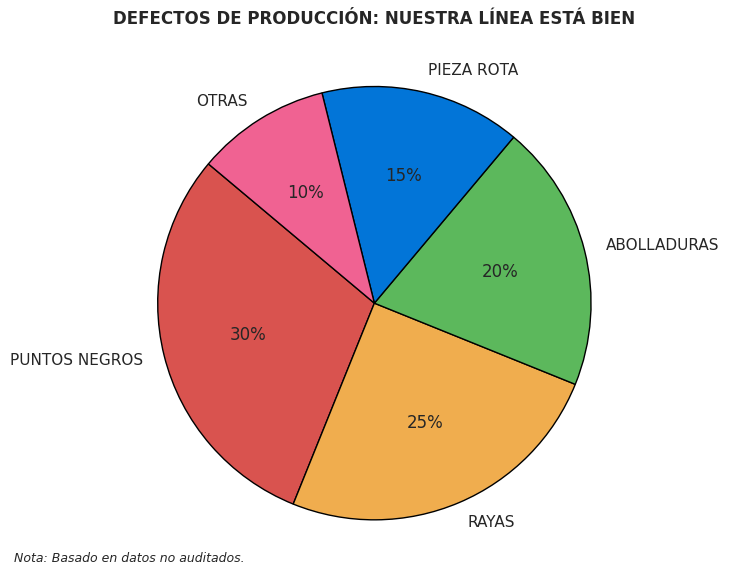

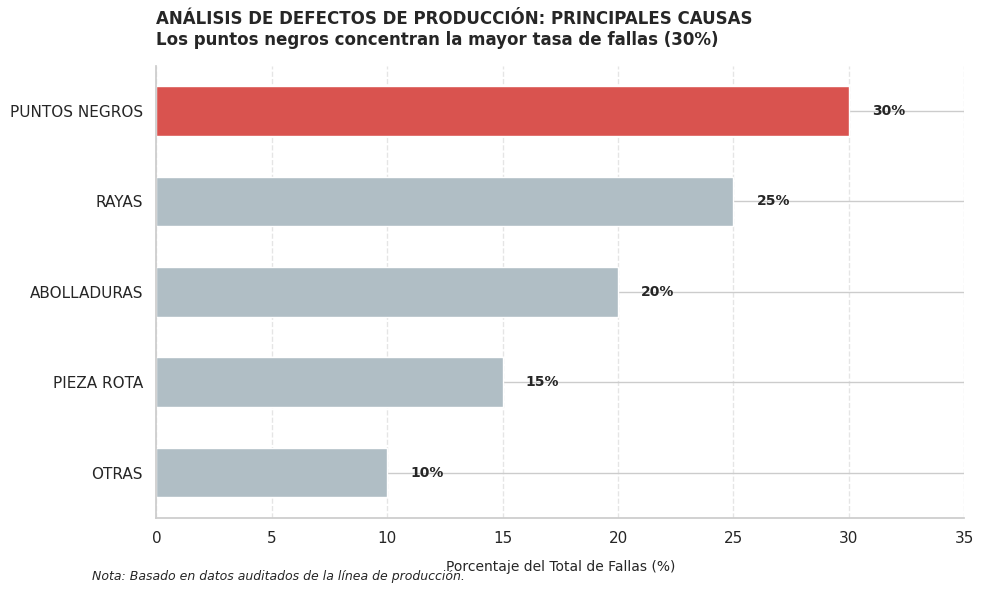

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Datos comunes para ambos gráficos
categorias = ["PUNTOS NEGROS", "RAYAS", "ABOLLADURAS", "PIEZA ROTA", "OTRAS"]
porcentajes = [30, 25, 20, 15, 10]
colores_pastel = ["#d9534f", "#f0ad4e", "#5cb85c", "#0275d8", "#f06292"]

# ==========================================
# 1. GRÁFICO "ANTES" (Diseño pobre / Torta 3D)
# ==========================================
plt.figure(figsize=(9, 6))

# Nota: Matplotlib no hace 3D real en pastel fácilmente,
# simulamos el efecto visual o usamos un pie chart estándar con subtítulo crítico.
plt.pie(
    porcentajes,
    labels=categorias,
    autopct="%1.0f%%",
    startangle=140,
    colors=colores_pastel,
    wedgeprops={"edgecolor": "black", "linewidth": 1, "antialiased": True},
)

plt.title(
    "DEFECTOS DE PRODUCCIÓN: NUESTRA LÍNEA ESTÁ BIEN",
    fontsize=12,
    fontweight="bold",
)
plt.figtext(
    0.1,
    0.05,
    "Nota: Basado en datos no auditados.",
    fontsize=9,
    style="italic",
)

plt.tight_layout()
plt.savefig("grafico_antes.png", dpi=300)
plt.show()

# ==========================================
# 2. GRÁFICO "DESPUÉS" (Rediseño óptimo / Barras)
# ==========================================
plt.figure(figsize=(10, 6))

# Ordenar los datos de mayor a menor para facilitar la lectura
datos_ordenados = sorted(
    zip(categorias, porcentajes), key=lambda x: x[1], reverse=False
)
cats_ord, pcts_ord = zip(*datos_ordenados)

# Uso de color con propósito: Destacar la barra principal en color fuerte y las demás en gris
colores_barras = [
    "#d9534f" if p == max(pcts_ord) else "#b0bec5" for p in pcts_ord
]

barras = plt.barh(cats_ord, pcts_ord, color=colores_barras, height=0.55)

# Título con conclusión clara
plt.title(
    "ANÁLISIS DE DEFECTOS DE PRODUCCIÓN: PRINCIPALES CAUSAS\nLos puntos negros concentran la mayor tasa de fallas (30%)",
    fontsize=12,
    fontweight="bold",
    pad=15,
    loc="left",
)
plt.xlabel("Porcentaje del Total de Fallas (%)", fontsize=10, labelpad=10)
plt.xlim(0, 35)

# Etiquetas directas de datos sobre las barras
for barra in barras:
  ancho = barra.get_width()
  plt.text(
      ancho + 1,
      barra.get_y() + barra.get_height() / 2,
      f"{ancho}%",
      va="center",
      ha="left",
      fontsize=10,
      fontweight="bold",
  )

# Limpieza estética del gráfico (estilo minimalista)
sns_colors = plt.gca()
sns_colors.spines["top"].set_visible(False)
sns_colors.spines["right"].set_visible(False)
sns_colors.spines["left"].set_color("#cccccc")
sns_colors.spines["bottom"].set_color("#cccccc")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.figtext(
    0.1,
    0.02,
    "Nota: Basado en datos auditados de la línea de producción.",
    fontsize=9,
    style="italic",
)

plt.tight_layout()
plt.savefig("grafico_despues.png", dpi=300)
plt.show()

### Justificación y Comparación del Rediseño Visual


| Elemento de Diseño | Gráfico "Antes" (Original) | Gráfico "Después" (Optimizado) |
| :--- | :--- | :--- |
| **Tipo de Gráfico** | Gráfico de pastel (torta). Dificulta comparar áreas angulares similares de forma rápida. | Gráfico de barras horizontales. Permite comparar longitudes en un mismo eje de manera exacta y natural. |
| **Orden de Datos** | Desordenado (aleatorio). No facilita la jerarquización de los problemas. | Ordenado de menor a mayor. Facilita la lectura visual instantánea y la identificación de prioridades. |
| **Uso del Color** | Multicolor sin propósito. Genera ruido cognitivo y compite por la atención del lector. | Monocromático neutro (gris) con color de énfasis (rojo) para destacar únicamente el punto crítico. |
| **Título e Insight** | Título decorativo/neutro e impreciso ("Nuestra línea está bien") que sesga y oculta el problema. | Título con enfoque narrativo y conclusión explícita que destaca de inmediato el dato más importante (30% fallas). |

**¿Qué se mejoró y por qué?**
Se transformó un diseño saturado y difícil de interpretar en una herramienta visual de toma de decisiones. Al eliminar el gráfico de pastel y usar barras horizontales limpias y ordenadas, se reduce el esfuerzo del cerebro para entender la información. El contraste de color focaliza la atención de inmediato en el problema prioritario (*Puntos Negros*), y las etiquetas de datos directas eliminan la necesidad de cuadrículas pesadas, haciendo la presentación final mucho más profesional y convincente.